# Diverging Bar Chart (Revenue Driver Classification)

## Исходные данные для построения

- датафрейм

In [6]:
driver_summary = pd.read_csv('driver_summary.csv', index_col = False)
driver_summary

,Revenue_Driver,Total_Revenue_Change,Total_Customers,Total_Revenue
0,Expansion,2740219.0,10469,40588914.0
1,Reactivation,355089.0,634,1256004.0
2,Acquisition,47976.0,112,175103.0
3,Churn,-1510818.0,3799,0.0
4,Contraction,-1689837.0,6864,9612504.0


## Код для построения

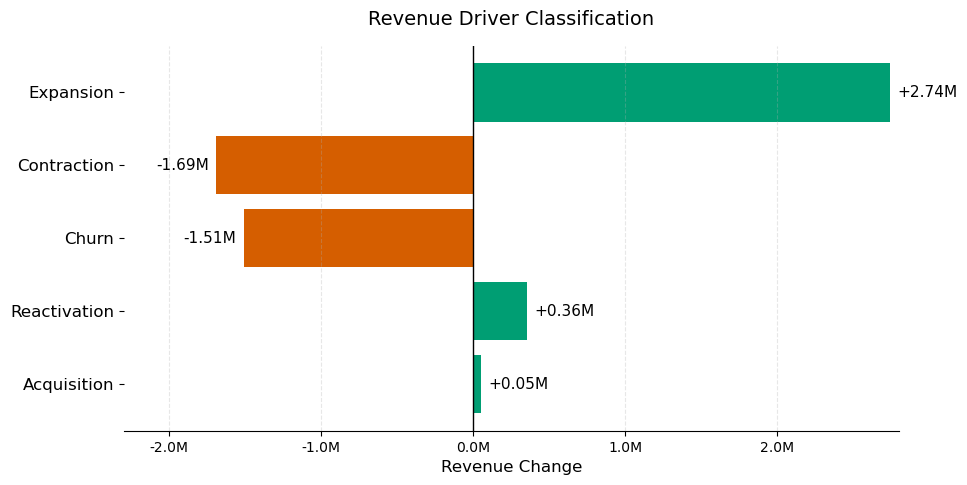

In [8]:
# =====================================================
# IMPORTS
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# =====================================================
# LOAD DATA
# =====================================================

driver_summary = pd.read_csv('driver_summary.csv', index_col = False)

# =====================================================
# The meaning of colors
# =====================================================

POSITIVE = '#009E73'
NEGATIVE = '#D55E00'

# =====================================
# PREPARE DATA
# =====================================

plot_df = (
    driver_summary
    .assign(
        Impact=lambda x: x['Total_Revenue_Change'].abs()
    )
    .sort_values('Impact')
)

# =====================================
# Colors
# =====================================

plot_df['Color'] = plot_df['Total_Revenue_Change'].apply(
    lambda x: POSITIVE if x > 0 else NEGATIVE    
)

# =====================================
# Figure
# =====================================

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_df['Revenue_Driver'],
    plot_df['Total_Revenue_Change'] / 1_000_000,
    color=plot_df['Color']
)

# =====================================
# Zero Line
# =====================================

ax.axvline(
    0,
    color='black',
    linewidth=1
)

# =====================================
# Labels
# =====================================

for bar in bars:

    width = bar.get_width()

    if width > 0:

        ax.text(
            width + 0.05,
            bar.get_y() + bar.get_height() / 2,
            f'+{width:.2f}M',
            va='center',
            ha='left',
            fontsize=11#,
            #fontweight='bold'
        )

    else:

        ax.text(
            width - 0.05,
            bar.get_y() + bar.get_height() / 2,
            f'{width:.2f}M',
            va='center',
            ha='right',
            fontsize=11#,
            #fontweight='bold'
        )

# =====================================
# Formatting
# =====================================

# Наименование и настройка осей
ax.set_title(
    'Revenue Driver Classification',
    fontsize=14,
    pad=15
)

ax.set_xlabel(
    'Revenue Change', fontsize=12
)

ax.set_ylabel('')

# Границы оси Х
ax.set_xlim(-2.3, 2.8)

# Настройка шрифта разметки оси
ax.tick_params(axis='y', labelsize=12)

def millions_formatter(x, pos):
    """Форматирует значения оси Y в миллионах с одним знаком"""
    return f'{x}M'

# Применяем форматтер к оси Y
ax.xaxis.set_major_formatter(FuncFormatter(millions_formatter))

# Настройка сетки
ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)

# Убрать рамку графика
sns.despine(
    left=True,
    bottom=False
)

#plt.savefig('revenue_driver_classification.png', dpi=300, bbox_inches='tight')

plt.show()

In [9]:
plot_df

,Revenue_Driver,Total_Revenue_Change,Total_Customers,Total_Revenue,Impact,Color
2,Acquisition,47976.0,112,175103.0,47976.0,#009E73
1,Reactivation,355089.0,634,1256004.0,355089.0,#009E73
3,Churn,-1510818.0,3799,0.0,1510818.0,#D55E00
4,Contraction,-1689837.0,6864,9612504.0,1689837.0,#D55E00
0,Expansion,2740219.0,10469,40588914.0,2740219.0,#009E73
